# code_157 · An original model with explicit typed decision heads

**Book:** section 30.3. Restart and run all cells using the [dedicated Python 3.12 CPU runtime](../CHAPTER_30_RUNTIME.md), not the earlier chapters' 3.14 environment. Generated inputs and the original fitted model are entirely internal; this laboratory needs no model files or downloads. Use the [guide](../CHAPTER_30_GUIDE.md), [execution evidence](../CHAPTER_30_EXECUTION.md), [asset manifest](../CHAPTER_30_ASSETS.md) and [registry](../CODE_EXAMPLES.md#code_157). Prerequisites: structured records, classification/probability and Chapter 8's evidence boundaries. Allow two minutes for execution and30–60 minutes to inspect the contracts.

All states, labels and mechanical examples are generated teaching cases, not field decisions or private records. Named local checkpoints are actually called where declared. No Jev hosted call, account spending or external action occurs. Original typed heads are not named-model substitutes. Output shape, factual correctness, probability calibration and authority to act remain separate questions. Source/development/calibration/final roles are declared locally; generated-instance novelty is not a guarantee of a novel task prior. Neural inference is explicit one-thread CPU float32. The literature cutoff remains18 October 2026.


In [1]:
import platform,time,json,copy,hashlib,sys,warnings
from pathlib import Path
import numpy as np,scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float32);torch.manual_seed(3957);torch.use_deterministic_algorithms(True)
START=time.perf_counter();SEED=3957;rng=np.random.default_rng(SEED);DISCLOSED_WARNINGS=[]
def render_warning(message,category,filename,lineno,file=None,line=None):
    location=filename.split('site-packages/')[-1] if 'site-packages/' in filename else 'code_157'
    DISCLOSED_WARNINGS.append({'category':category.__name__,'message':str(message)})
    print(f'{location}:{lineno}: {category.__name__}: {message}',file=file or sys.stderr)
warnings.showwarning=render_warning
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}
def parameter_digest(network):
    digest=hashlib.sha256()
    for parameter in network.parameters():digest.update(parameter.detach().cpu().numpy().tobytes())
    return digest.hexdigest()


{'python': '3.12.13', 'numpy': '2.5.3', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.1', 'threadpoolctl': '3.7.0', 'torch': '2.8.0'}
CPU: Darwin arm64 seed: 3957


<a id="own-typed-interface"></a>
 ## Train three actual heads without claiming an open-language interface
 An original small neural trunk predicts a three-option priority, a five-level severity distribution and a yes/no event probability. It accepts five fixed numeric measurements; arbitrary questions or rubrics are unsupported. Generated120 buildings each supply six members, split80 source/20 development/20 final. Source-only scaling precedes600 Adam updates at0.01; development selects every 50 updates using a fixed sum of the three losses. The targets are constructed noisy teaching outcomes, not structural safety labels. Pydantic schemas validate allowed choices, finite normalized probability vectors, bounded expected severity and yes/no probability. Correctness is independently assessed against final targets; a schema-valid deliberately wrong fixture proves why those checks have different roles. This original multihead model is not Jev, Laya or Kev.


,metric,value
0,Priority accuracy,0.825000
1,Priority multiclass Brier,0.218493
2,Severity expected-level MAE,0.285161
3,Event Brier,0.065367


Policy counts: {'priority_queue': 16, 'review': 16, 'routine_queue': 15, 'urgent_review': 73}


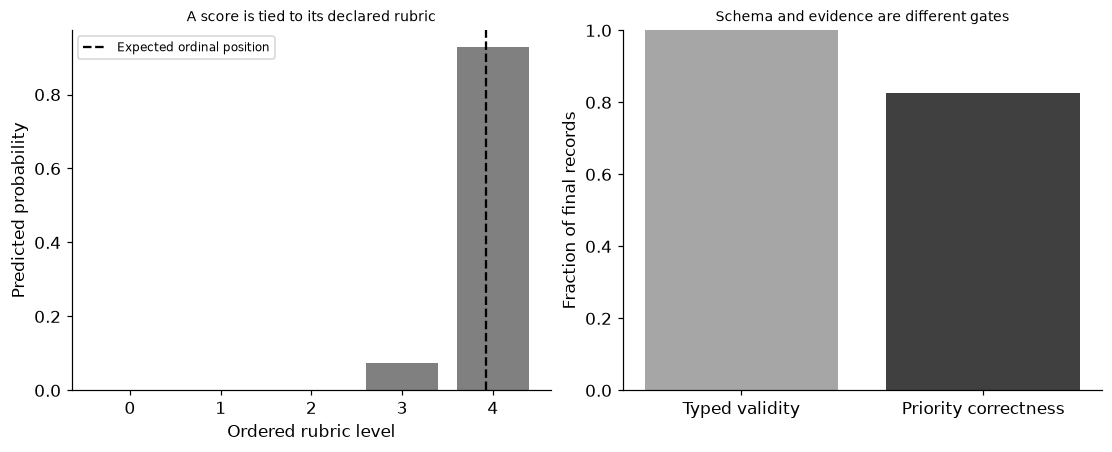

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from pydantic import BaseModel,Field,model_validator,ValidationError
from typing import Literal
VERSIONS['pydantic']=__import__('importlib.metadata',fromlist=['version']).version('pydantic')
groups=np.repeat(np.arange(120),6);building_effect=rng.normal(0,.12,120);raw=np.column_stack([rng.uniform(.1,1.5,720),rng.uniform(.02,.7,720),rng.uniform(0,.5,720),rng.uniform(0,2,720),rng.uniform(.3,1.4,720)]).astype(np.float32);raw[:,0]=np.clip(raw[:,0]+building_effect[groups],.01,None)
latent=1.1*raw[:,0]+1.4*raw[:,1]+.5*raw[:,2]+building_effect[groups]+rng.normal(0,.1,720);severity=np.digitize(latent,[.65,1,1.4,1.9]);priority=np.where(severity<=1,0,np.where(severity==2,1,2));event=(raw[:,0]+.5*raw[:,1]+.3*raw[:,2]+rng.normal(0,.12,720)>1.3).astype(np.float32)
source=groups<80;development=(groups>=80)&(groups<100);final=groups>=100;assert not set(groups[source])&set(groups[final]);scaler=StandardScaler().fit(raw[source]);X=torch.tensor(scaler.transform(raw).astype(np.float32));P=torch.tensor(priority);S=torch.tensor(severity);Y=torch.tensor(event)
class TypedHeads(nn.Module):
    def __init__(self):super().__init__();self.trunk=nn.Sequential(nn.Linear(5,24),nn.ReLU(),nn.Linear(24,24),nn.ReLU());self.priority=nn.Linear(24,3);self.severity=nn.Linear(24,5);self.event=nn.Linear(24,1)
    def forward(self,x):h=self.trunk(x);return self.priority(h),self.severity(h),self.event(h).squeeze(-1)
def objective(output,mask):
    p,s,e=output;return nn.functional.cross_entropy(p,P[mask])+.5*nn.functional.cross_entropy(s,S[mask])+.5*nn.functional.binary_cross_entropy_with_logits(e,Y[mask])
network=TypedHeads();opt=torch.optim.Adam(network.parameters(),lr=.01);best=np.inf;trace=[]
for step in range(600):
    opt.zero_grad();loss=objective(network(X[source]),source);loss.backward();opt.step()
    if (step+1)%50==0:
        with torch.no_grad():score=float(objective(network(X[development]),development))
        trace.append((step+1,score))
        if score<best:best=score;selected_update=step+1;best_state=copy.deepcopy(network.state_dict())
network.load_state_dict(best_state);network.eval()
with torch.no_grad():pl,sl,el=network(X[final]);p=pl.softmax(1).numpy();s=sl.softmax(1).numpy();e=el.sigmoid().numpy()
NAMES=['routine','soon','urgent']
class ChoiceAnswer(BaseModel):
    choice:Literal['routine','soon','urgent'];probabilities:dict[str,float]
    @model_validator(mode='after')
    def valid_distribution(self):
        values=list(self.probabilities.values())
        if set(self.probabilities)!=set(NAMES) or not np.isfinite(values).all() or min(values)<0 or max(values)>1 or abs(sum(values)-1)>2e-6:raise ValueError('invalid choice distribution')
        if self.choice!=max(self.probabilities,key=self.probabilities.get):raise ValueError('choice must match distribution argmax')
        return self
class ScoreAnswer(BaseModel):
    score:float=Field(ge=0,le=4);probabilities:dict[str,float]
    @model_validator(mode='after')
    def valid_distribution(self):
        if set(self.probabilities)!=set(map(str,range(5))):raise ValueError('five severity levels required')
        values=[self.probabilities[str(i)] for i in range(5)]
        if not np.isfinite(values).all() or min(values)<0 or max(values)>1 or abs(sum(values)-1)>2e-6 or abs(self.score-np.dot(values,np.arange(5)))>2e-5:raise ValueError('invalid ordinal expectation')
        return self
class YesNoAnswer(BaseModel):
    probability_yes:float=Field(ge=0,le=1)
    @model_validator(mode='after')
    def finite(self):
        if not np.isfinite(self.probability_yes):raise ValueError('probability must be finite')
        return self
answers=[]
for pp,ss,ee in zip(p,s,e):answers.append({'priority':ChoiceAnswer(choice=NAMES[int(pp.argmax())],probabilities={k:float(v) for k,v in zip(NAMES,pp)}),'severity':ScoreAnswer(score=float(ss@np.arange(5)),probabilities={str(i):float(v) for i,v in enumerate(ss)}),'event':YesNoAnswer(probability_yes=float(ee))})
invalid_fixtures=[(ChoiceAnswer,{'choice':'deploy','probabilities':{'routine':1.,'soon':0.,'urgent':0.}}),(ChoiceAnswer,{'choice':'routine','probabilities':{'routine':1.1,'soon':-.1,'urgent':0.}}),(ScoreAnswer,{'score':5.,'probabilities':dict(zip(map(str,range(5)),[0.,0.,0.,0.,1.]))}),(YesNoAnswer,{'probability_yes':float('nan')})];rejected=0
for schema,fixture in invalid_fixtures:
    try:schema(**fixture)
    except ValidationError:rejected+=1
assert rejected==4
valid_wrong=ChoiceAnswer(choice='routine',probabilities={'routine':1.,'soon':0.,'urgent':0.});urgent_rows=np.flatnonzero(priority[final]==2);assert len(urgent_rows)>0 and valid_wrong.choice!=NAMES[priority[final][urgent_rows[0]]]
def software_policy(answer,evidence_available=True):
    if not evidence_available or max(answer['priority'].probabilities.values())<.7:return 'review'
    return {'routine':'routine_queue','soon':'priority_queue','urgent':'urgent_review'}[answer['priority'].choice]
routes=[software_policy(a) for a in answers];routes_missing=[software_policy(a,False) for a in answers];assert set(routes_missing)=={'review'}
severity_prediction=s@np.arange(5);rows=[{'metric':'Priority accuracy','value':float(accuracy_score(priority[final],p.argmax(1)))},{'metric':'Priority multiclass Brier','value':float(np.mean(np.sum((p-np.eye(3)[priority[final]])**2,axis=1)))},{'metric':'Severity expected-level MAE','value':float(np.mean(np.abs(severity_prediction-severity[final])))},{'metric':'Event Brier','value':float(np.mean((e-event[final])**2))}]
RESULTS.update(source_buildings=80,development_buildings=20,final_buildings=20,members_per_building=6,optimizer_updates=600,learning_rate=.01,selected_update=selected_update,development_objective=best,parameters=sum(q.numel() for q in network.parameters()),final_outputs=120,valid_typed_outputs=len(answers),invalid_fixtures_rejected=rejected,valid_but_wrong_fixture_accepted=True,metrics=rows,policy_counts={r:routes.count(r) for r in sorted(set(routes))},missing_evidence_review_count=routes_missing.count('review'),task_support='Five numeric fields and three fixed learned heads; arbitrary language questions unsupported.');display(pd.DataFrame(rows));print('Policy counts:',RESULTS['policy_counts'])
fig,axes=plt.subplots(1,2,figsize=(10,4));xx=np.arange(5);axes[0].bar(xx,s[0],color='.5');axes[0].axvline(severity_prediction[0],color='black',linestyle='--',label='Expected ordinal position');axes[0].set(xticks=xx,xlabel='Ordered rubric level',ylabel='Predicted probability',title='A score is tied to its declared rubric');axes[0].legend(fontsize=8)
axes[1].bar(['Typed validity','Priority correctness'],[1,rows[0]['value']],color=['.65','.25']);axes[1].set(ylim=(0,1),ylabel='Fraction of final records',title='Schema and evidence are different gates');plt.show()


<a id="typed-contract-and-policy"></a>
 ## A typed interface does not create a new scientific task category
 The choice head is classification, the severity head predicts a distribution over ordered levels and the yes/no head is binary probabilistic prediction. Shared software types make these outputs composable without guaranteeing truth or a physical interpretation of their probabilities. The score uses positions 0–4 in a constructed rubric, not a measured damage unit. A deterministic policy validates evidence availability and uses a fixed illustrative 0.7 top-probability gate; it is not a validated deferral policy. Chapter 30.5separately chooses thresholds using development evidence. No queue or external application is actually changed.


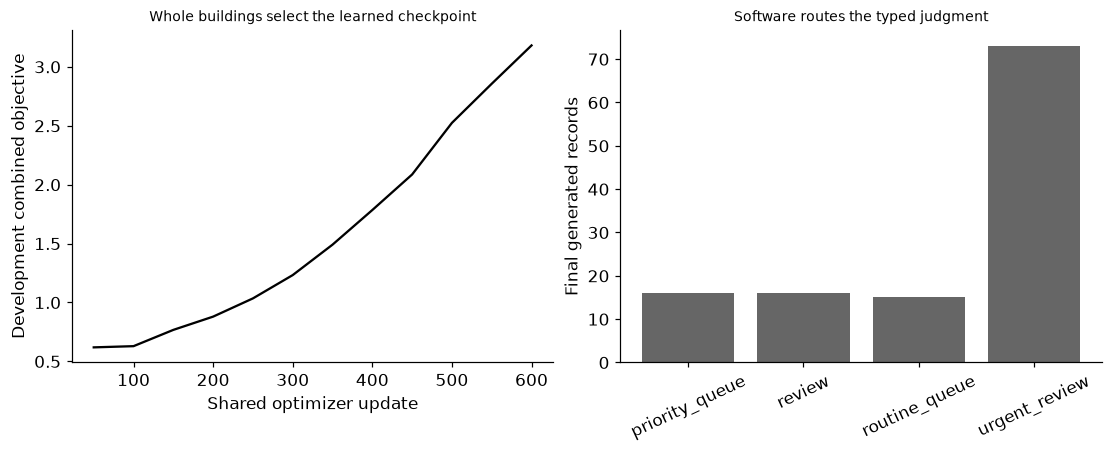

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));h=np.array(trace);axes[0].plot(h[:,0],h[:,1],color='black');axes[0].set(xlabel='Shared optimizer update',ylabel='Development combined objective',title='Whole buildings select the learned checkpoint');names=list(RESULTS['policy_counts']);axes[1].bar(names,[RESULTS['policy_counts'][k] for k in names],color='.4');axes[1].set(ylabel='Final generated records',title='Software routes the typed judgment');axes[1].tick_params(axis='x',rotation=25);plt.show()
assert len(answers)==120 and len(rows)==4 and np.isfinite(severity_prediction).all()


In [4]:
summary={'example_id':'code_157','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual own multihead neural prediction from structured generated states', 'separate choice ordinal-score and yes-no output contracts', 'whole-building training and development selection', 'schema-valid yet incorrect counterexample and rejected invalid fixtures', 'deterministic software policy separated from model judgment'],'results':RESULTS,'disclosed_warnings':DISCLOSED_WARNINGS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual own multihead neural prediction from structured generated states", "separate choice ordinal-score and yes-no output contracts", "whole-building training and development selection", "schema-valid yet incorrect counterexample and rejected invalid fixtures", "deterministic software policy separated from model judgment"], "disclosed_warnings": [], "elapsed_seconds": 0.693, "example_id": "code_157", "hardware": "Darwin arm64 CPU", "results": {"development_buildings": 20, "development_objective": 0.6190688610076904, "final_buildings": 20, "final_outputs": 120, "invalid_fixtures_rejected": 4, "learning_rate": 0.01, "members_per_building": 6, "metrics": [{"metric": "Priority accuracy", "value": 0.825}, {"metric": "Priority multiclass Brier", "value": 0.2184932958973917}, {"metric": "Severity expected-level MAE", "value": 0.28516077252139815}, {"metric": "Event Brier", "value": 0.06536716222763062}], "missing_evidence_review_count": 120,